# 01 - Exploratory Data Analysis & Data Pipeline

**Owner:** Shubham Behri

### Objectives:
- Load raw space-separated german.data with correct column headers and no data loss.
- Recode the target variable so that BAD = 1 (positive class) and GOOD = 0 (negative class).
- Verify special category encodings (e.g. A65 unknown savings, A124 no property) as distinct categories rather than missing data.
- Explore univariate numerical distributions, categorical proportions, and bivariate relationships with credit risk.
- Provide written domain interpretations and lay the foundation for preprocessing and feature engineering.



## Section 1: Data Ingestion & Schema Verification


### Interpretation

*Write your interpretation here.*


In [2]:
import pandas as pd
import numpy as np

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

# Define column names
column_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_duration",
    "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "people_liable",
    "telephone", "foreign_worker", "credit_risk"
]

# Load raw dataset
df = pd.read_csv(url, sep=r"\s+", header=None, names=column_names)

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Data type verification
print("\nData Types:")
print(df.dtypes)

# Schema verification
assert df.shape == (1000, 21), "Incorrect dataset dimensions!"
assert df.columns.tolist() == column_names, "Column names mismatch!"

print("\nSECTION 1 COMPLETED SUCCESSFULLY!")
print("1000 Records | 21 Columns | Schema Verified")

Dataset Shape: (1000, 21)

First Five Records:


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Column Names:
['checking_account', 'duration_months', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_account         1000 non-null   str  
 1   duration_months          1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_account          1000 non-null   str  
 6   employment_duration      1000 non-null   str  
 7   installment_rate         1000 non-null   

## Section 2: Target Variable Distribution & Recoding (BAD=1, GOOD=0)


### Interpretation

*Write your interpretation here.*


Original Target Distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64

Recoded Target Distribution:
risk_label
GOOD    700
BAD     300
Name: count, dtype: int64

Target Class Summary:


,Credit_Category,Encoded_Value,Customer_Count,Percentage
0,GOOD,0,700,70.0
1,BAD,1,300,30.0



Positive Class (BAD): 300
Negative Class (GOOD): 700


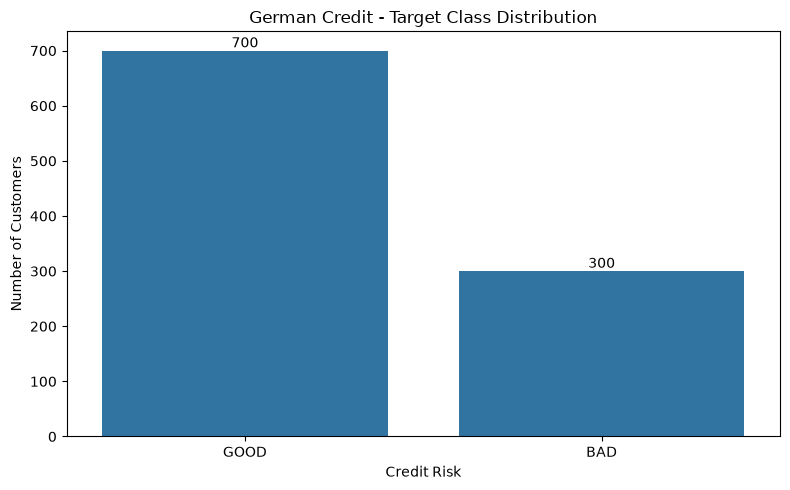

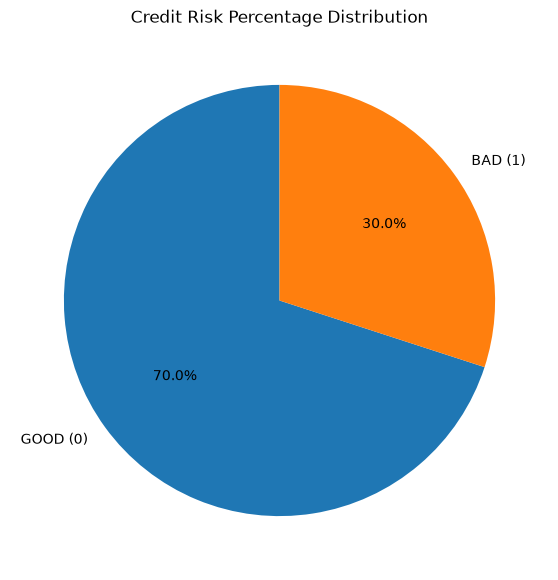


Class Imbalance Ratio: 2.33
The dataset has class imbalance.

Target Encoding Verified Successfully!

DOMAIN INTERPRETATION
---------------------------------------
1. GOOD credit customers represent 70% of the dataset.
2. BAD credit customers represent 30% of the dataset.
3. BAD credit (1) is the positive class.
4. GOOD credit (0) is the negative class.
5. The dataset has a 70:30 class distribution.
6. Accuracy alone may not be sufficient for model evaluation.
7. Precision, Recall, F1-score and Confusion Matrix
   should also be considered during model evaluation.

Saved: german_credit_target_encoded.csv

SECTION 2 COMPLETED SUCCESSFULLY
Total Records: 1000
GOOD (0): 700
BAD (1): 300
Target Encoding: VERIFIED


In [3]:

# ============================================================
# SECTION 2 - TARGET VARIABLE RECODING & VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. VERIFY ORIGINAL TARGET VALUES
print("Original Target Distribution:")
print(df["credit_risk"].value_counts().sort_index())

assert set(df["credit_risk"].unique()) == {1, 2}, "Unexpected target values!"

# 2. RECODE TARGET VARIABLE
# Original 1 = GOOD, 2 = BAD
# New 0 = GOOD, 1 = BAD

target_mapping = {
    1: 0,
    2: 1
}

df["credit_risk"] = df["credit_risk"].map(target_mapping)

assert df["credit_risk"].notna().all()

df["credit_risk"] = df["credit_risk"].astype(int)

# 3. CREATE READABLE LABELS
df["risk_label"] = df["credit_risk"].map({
    0: "GOOD",
    1: "BAD"
})

# 4. DISPLAY TARGET DISTRIBUTION
print("\nRecoded Target Distribution:")
print(df["risk_label"].value_counts())

# 5. CALCULATE CLASS COUNTS AND PERCENTAGES
class_counts = df["credit_risk"].value_counts().sort_index()
class_percentages = df["credit_risk"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Credit_Category": ["GOOD", "BAD"],
    "Encoded_Value": [0, 1],
    "Customer_Count": [class_counts[0], class_counts[1]],
    "Percentage": [class_percentages[0], class_percentages[1]]
})

print("\nTarget Class Summary:")
display(target_summary)

# 6. POSITIVE AND NEGATIVE CLASS IDENTIFICATION
positive_class = df[df["credit_risk"] == 1]
negative_class = df[df["credit_risk"] == 0]

print("\nPositive Class (BAD):", len(positive_class))
print("Negative Class (GOOD):", len(negative_class))

# 7. BAR CHART
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="risk_label",
    order=["GOOD", "BAD"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("German Credit - Target Class Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 8. PIE CHART
plt.figure(figsize=(7, 7))

plt.pie(
    [class_counts[0], class_counts[1]],
    labels=["GOOD (0)", "BAD (1)"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Credit Risk Percentage Distribution")
plt.show()

# 9. CLASS IMBALANCE ANALYSIS
imbalance_ratio = len(negative_class) / len(positive_class)

print("\nClass Imbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("The dataset has class imbalance.")
else:
    print("The dataset has relatively balanced classes.")

# 10. TARGET ENCODING VALIDATION
assert df["credit_risk"].isin([0, 1]).all()
assert df["credit_risk"].value_counts()[0] == 700
assert df["credit_risk"].value_counts()[1] == 300
assert df["risk_label"].notna().all()

print("\nTarget Encoding Verified Successfully!")

# 11. DOMAIN INTERPRETATION
print("\nDOMAIN INTERPRETATION")
print("---------------------------------------")
print("1. GOOD credit customers represent 70% of the dataset.")
print("2. BAD credit customers represent 30% of the dataset.")
print("3. BAD credit (1) is the positive class.")
print("4. GOOD credit (0) is the negative class.")
print("5. The dataset has a 70:30 class distribution.")
print("6. Accuracy alone may not be sufficient for model evaluation.")
print("7. Precision, Recall, F1-score and Confusion Matrix")
print("   should also be considered during model evaluation.")

# 12. SAVE RECODED DATASET
df.to_csv("german_credit_target_encoded.csv", index=False)

print("\nSaved: german_credit_target_encoded.csv")

# 13. FINAL SUMMARY
print("\n======================================")
print("SECTION 2 COMPLETED SUCCESSFULLY")
print("======================================")
print("Total Records:", len(df))
print("GOOD (0):", len(negative_class))
print("BAD (1):", len(positive_class))
print("Target Encoding: VERIFIED")


## Section 3: Numerical Features: Distributions, Skewness & Outliers


### Interpretation

*Write your interpretation here.*


Numerical Features:
['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable']

Total Numerical Features: 7

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
people_liable,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0



SKEWNESS ANALYSIS


,Skewness,Distribution
duration_months,1.094,Highly Right Skewed
credit_amount,1.950,Highly Right Skewed
installment_rate,-0.531,Moderately Left Skewed
residence_since,-0.273,Approximately Symmetric
age,1.021,Highly Right Skewed
existing_credits,1.273,Highly Right Skewed
people_liable,1.909,Highly Right Skewed


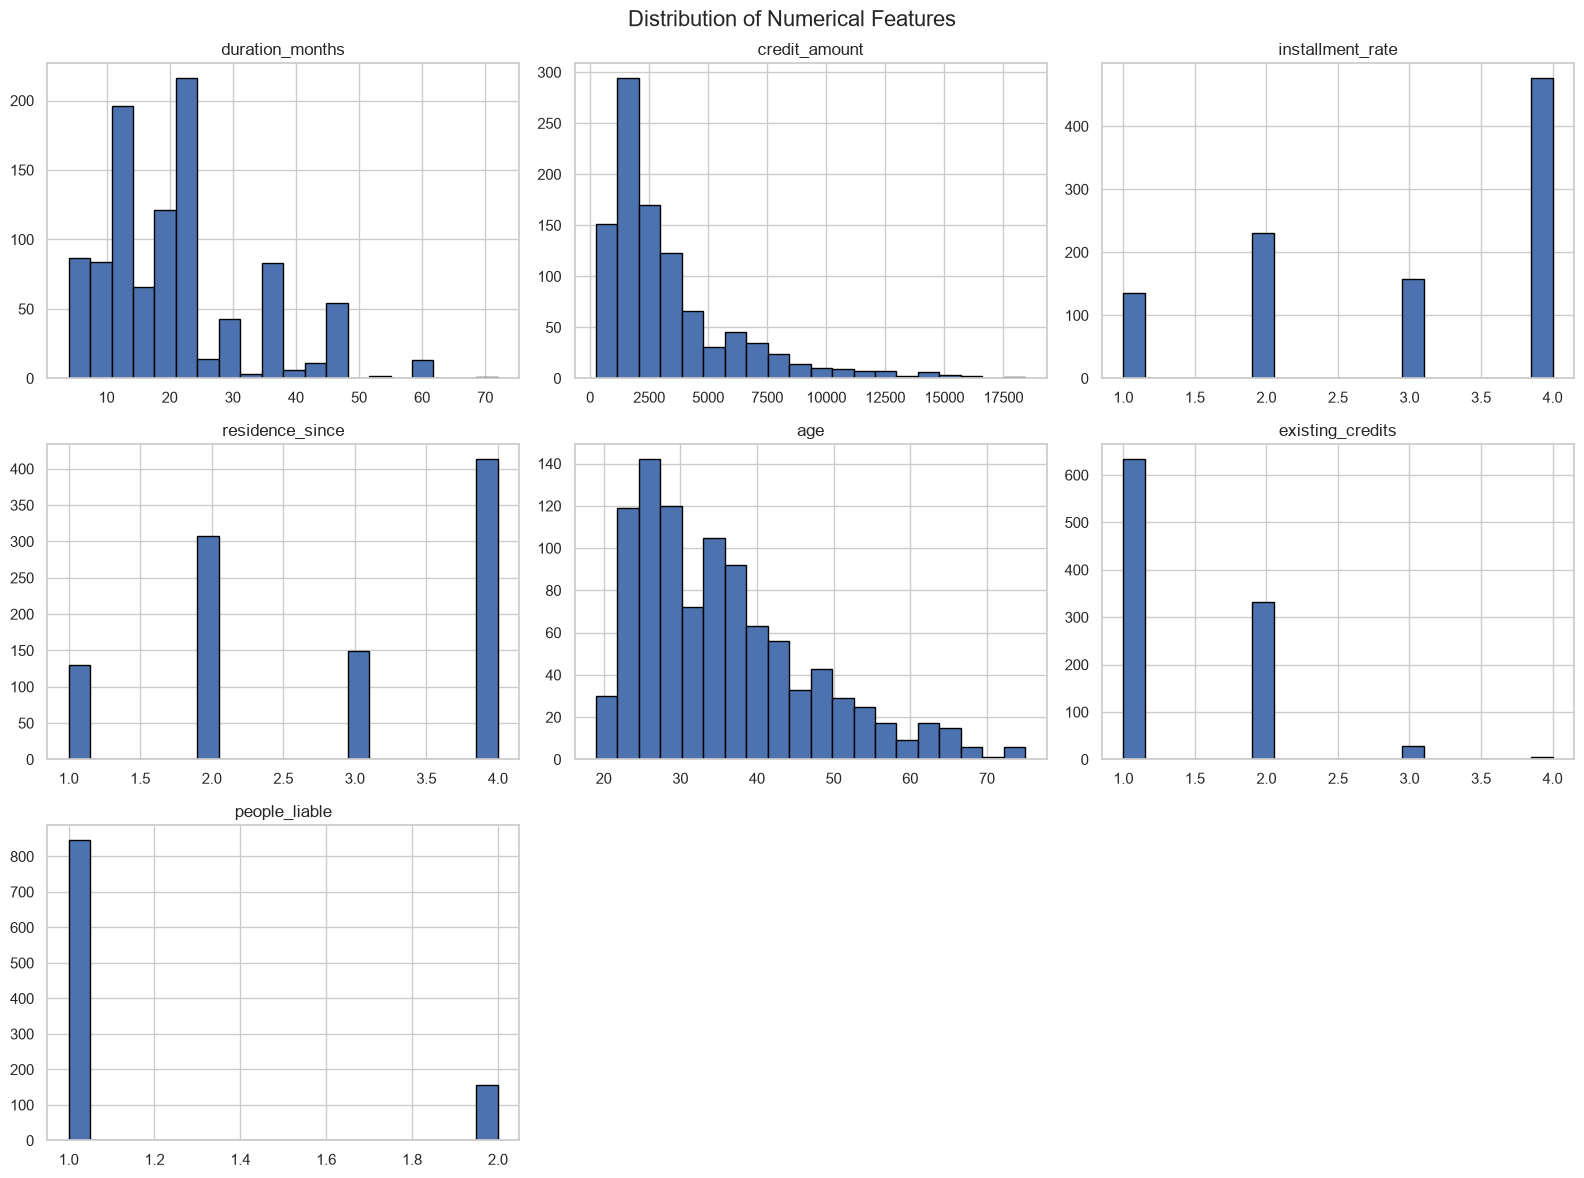

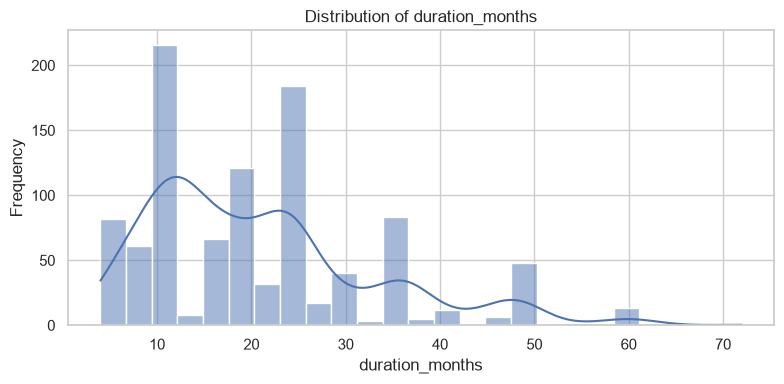

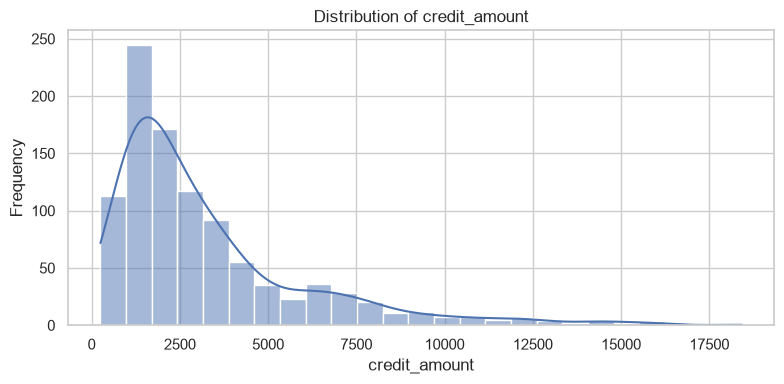

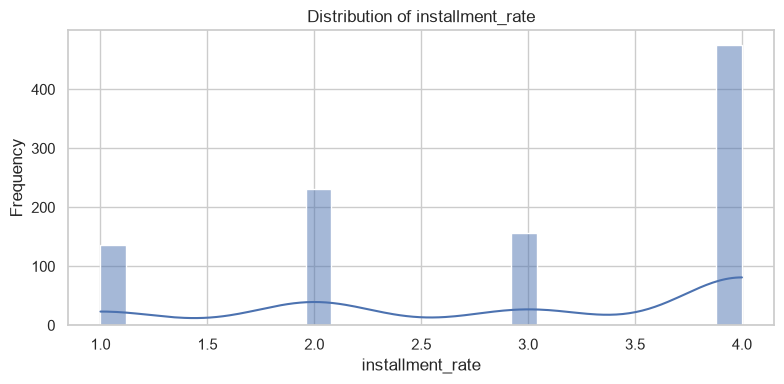

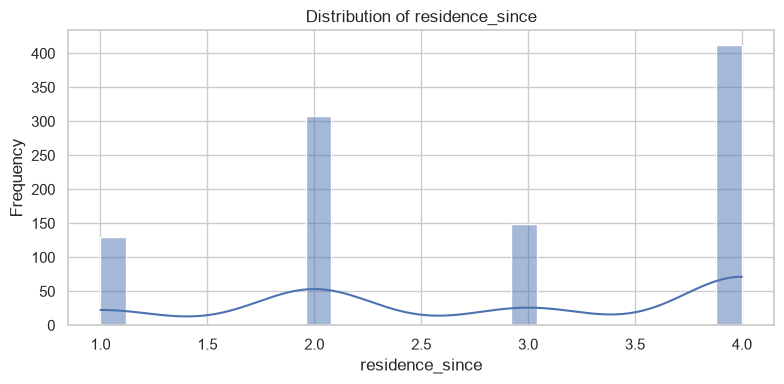

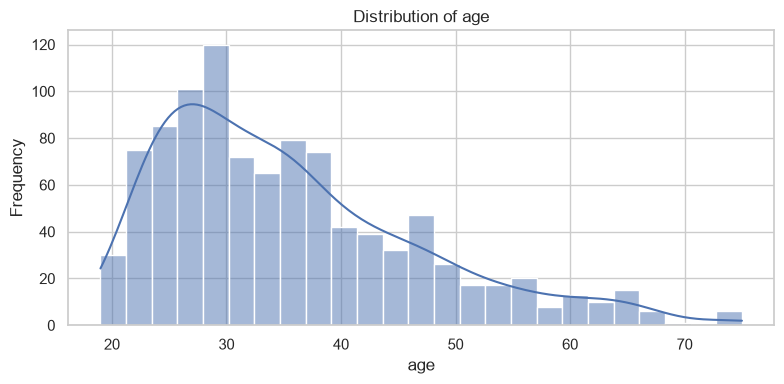

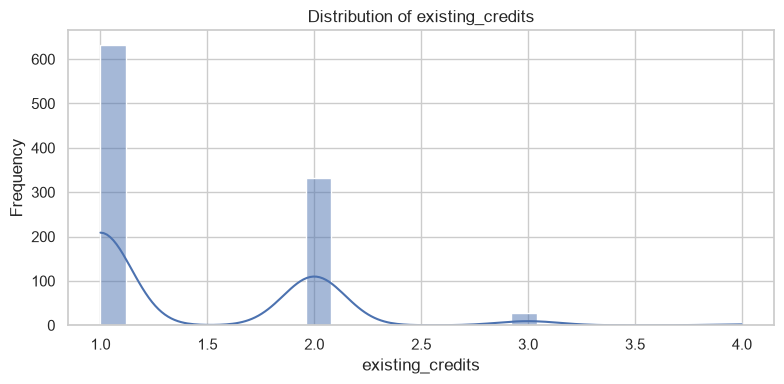

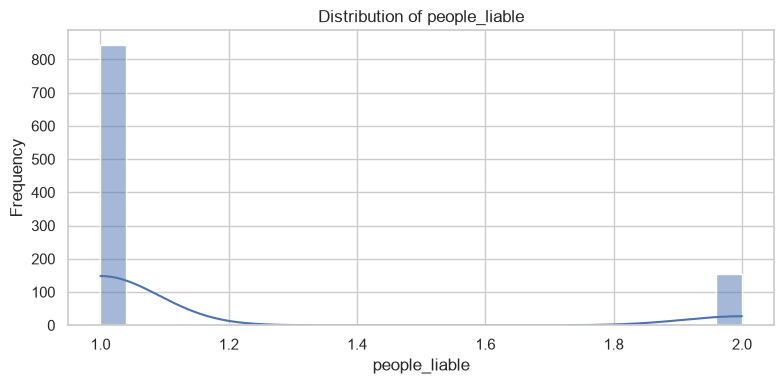


OUTLIER DETECTION SUMMARY


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,duration_months,12.0,24.00,12.00,-6.00,42.00,70,7.0
1,credit_amount,1365.5,3972.25,2606.75,-2544.62,7882.38,72,7.2
2,installment_rate,2.0,4.00,2.00,-1.00,7.00,0,0.0
3,residence_since,2.0,4.00,2.00,-1.00,7.00,0,0.0
4,age,27.0,42.00,15.00,4.50,64.50,23,2.3
5,existing_credits,1.0,2.00,1.00,-0.50,3.50,6,0.6
6,people_liable,1.0,1.00,0.00,1.00,1.00,155,15.5


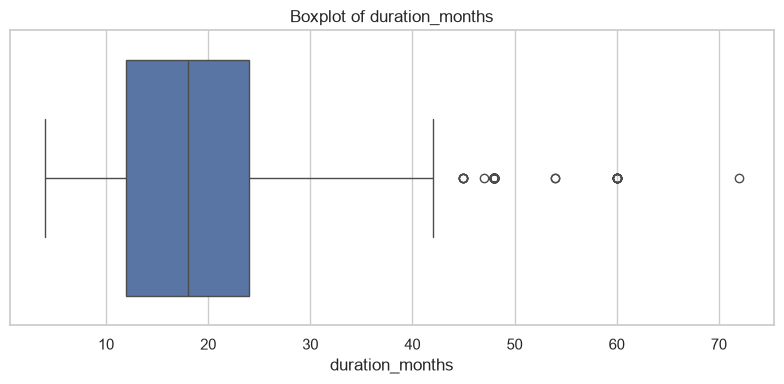

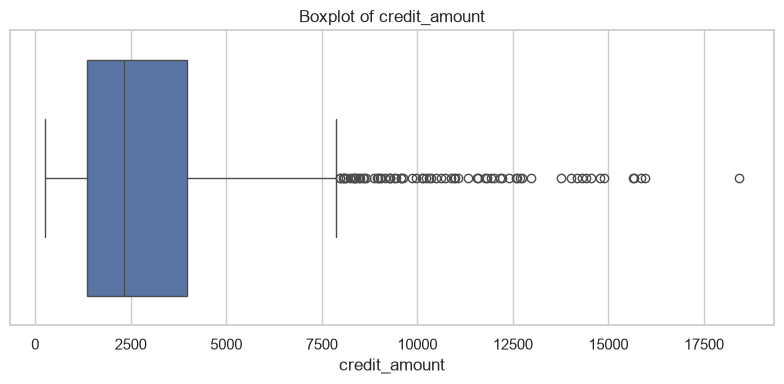

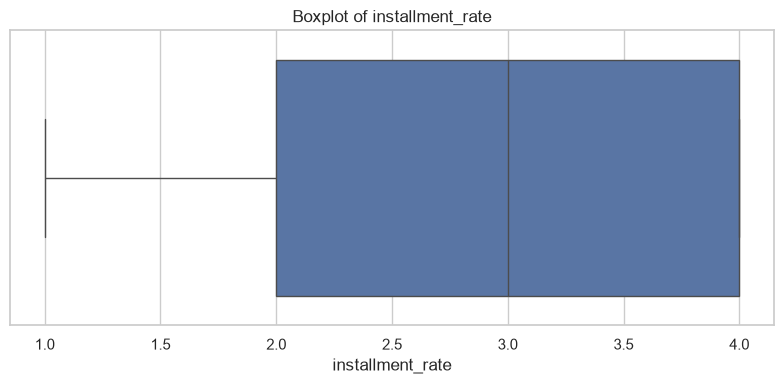

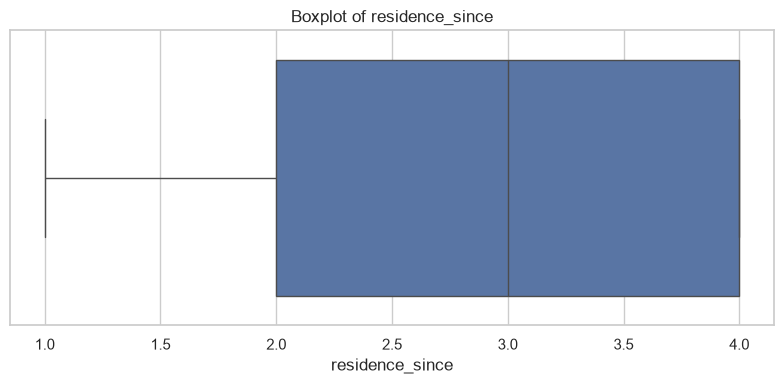

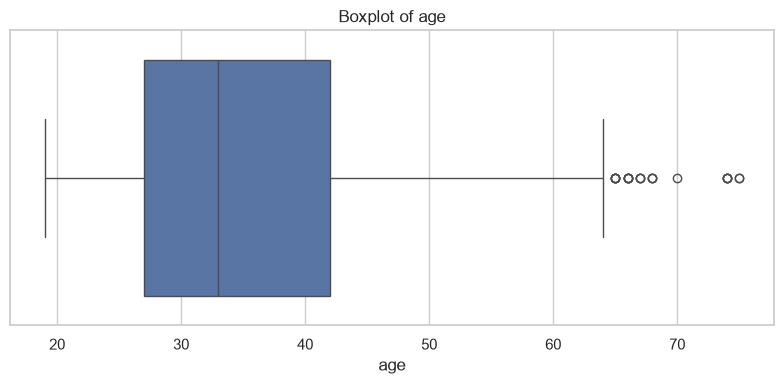

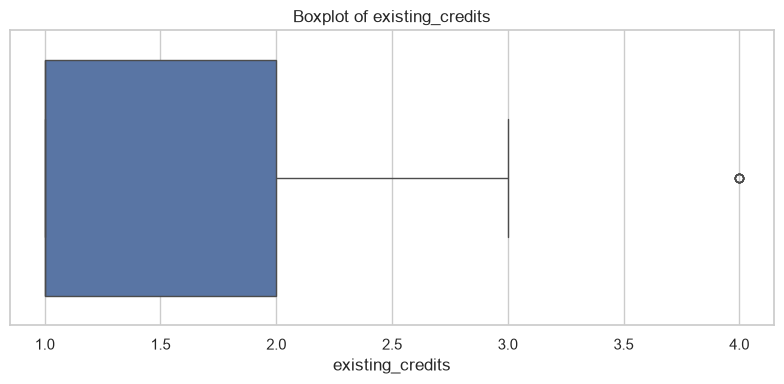

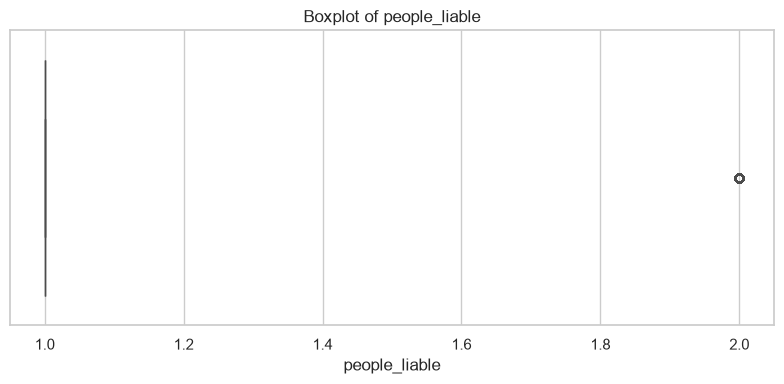

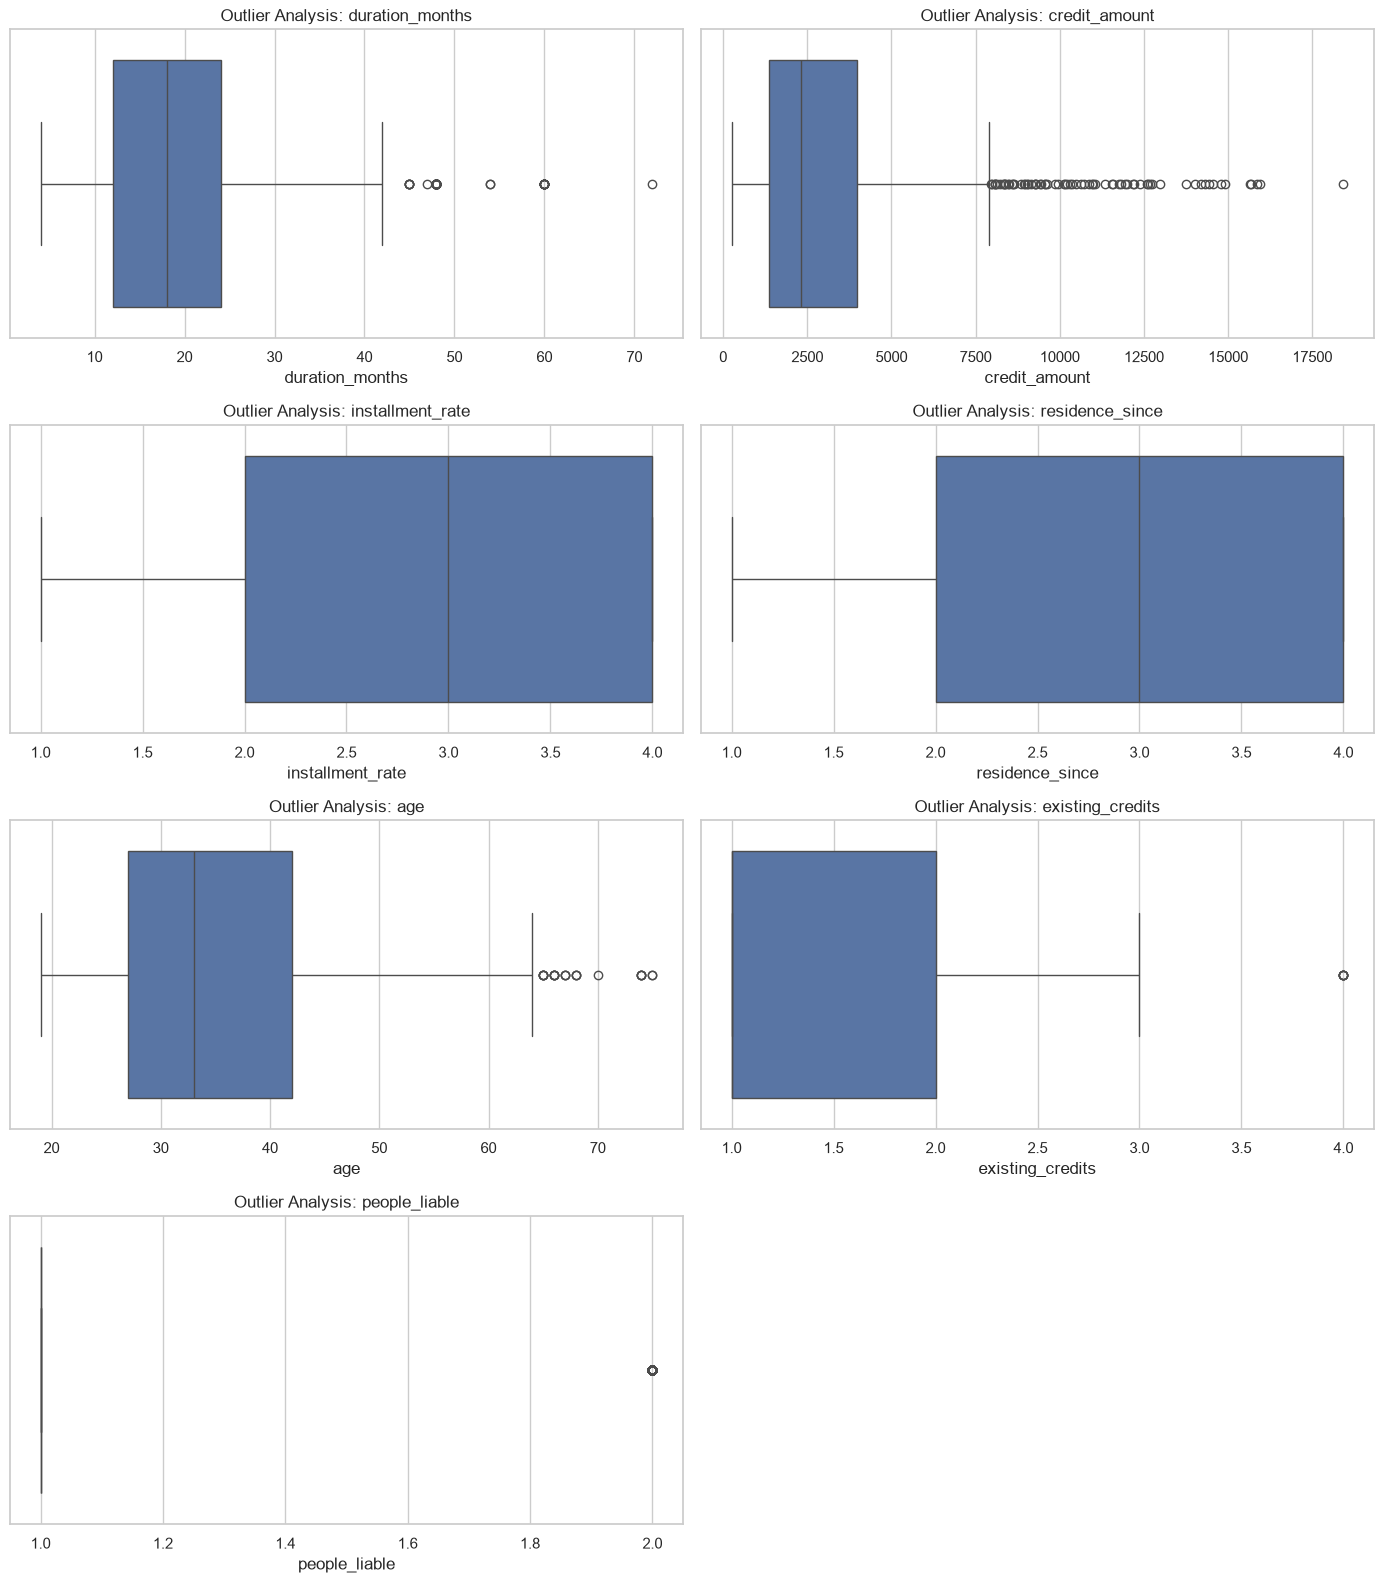

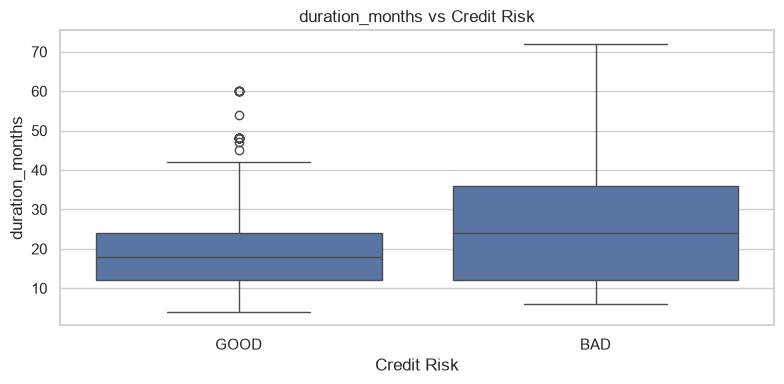

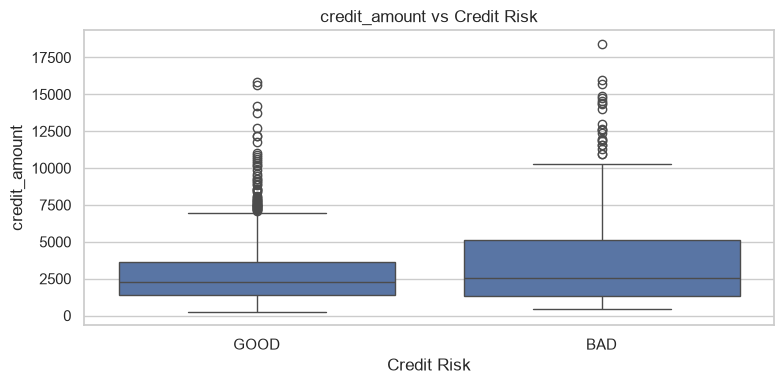

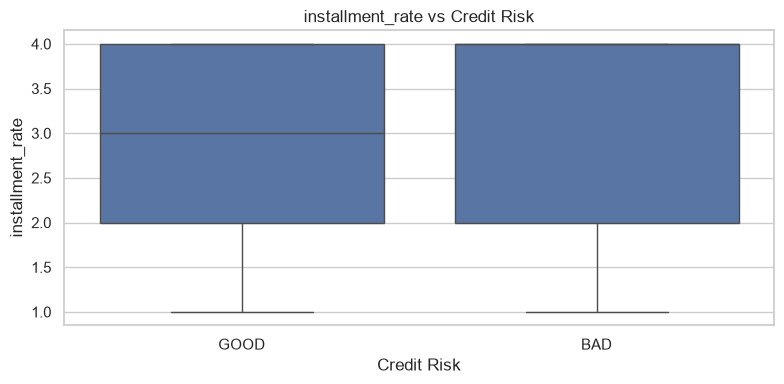

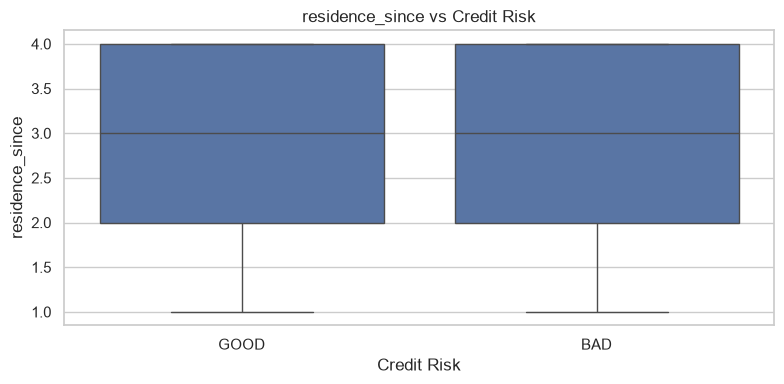

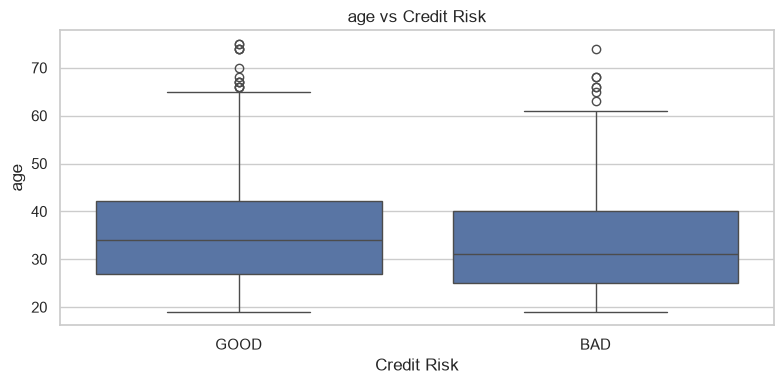

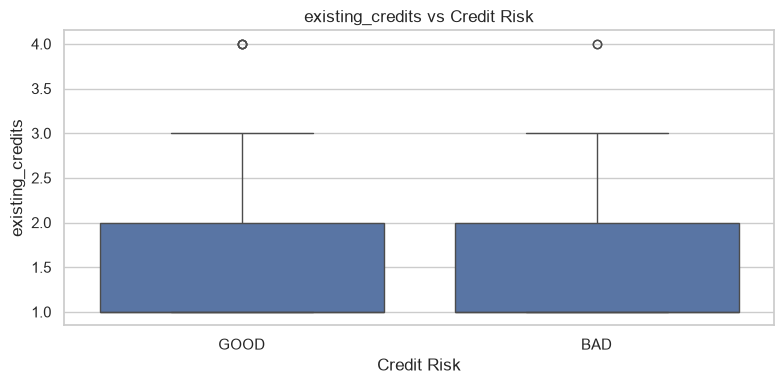

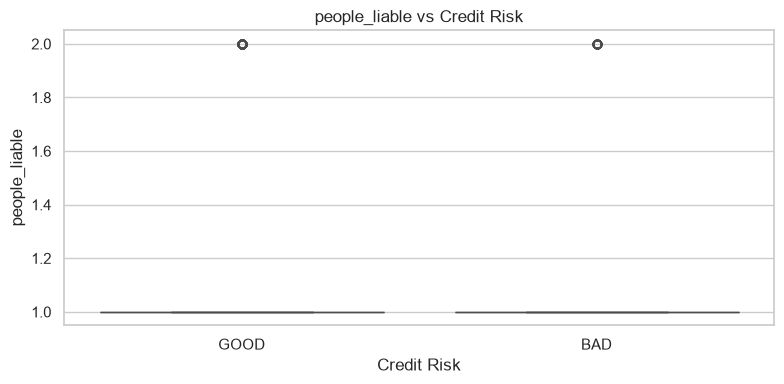


NUMERICAL FEATURES BY CREDIT RISK


duration_months               credit_amount                   \
                      mean median    std          mean  median      std   
risk_label                                                                
BAD                  24.86   24.0  13.28       3938.13  2574.5  3535.82   
GOOD                 19.21   18.0  11.08       2985.46  2244.0  2401.47   

           installment_rate              residence_since  ...          age  \
                       mean median   std            mean  ...   std   mean   
risk_label                                                ...                
BAD                    3.10    4.0  1.09            2.85  ...  1.09  33.96   
GOOD                   2.92    3.0  1.13            2.84  ...  1.11  36.22   

                         existing_credits              people_liable         \
           median    std             mean median   std          mean median   
risk_label                                                                    
BAD          31.0  11.22             1.37    1.0  0.56          1.15    1.0   
GOOD         34.0  11.38             1.42    1.0  0.58          1.16    1.0   

                  
             std  
risk_label        
BAD         0.36  
GOOD        0.36  

[2 rows x 21 columns]


DOMAIN INTERPRETATION
------------------------------------------------
duration_months: Right-skewed distribution.
credit_amount: Right-skewed distribution.
installment_rate: Left-skewed distribution.
residence_since: Approximately symmetric distribution.
age: Right-skewed distribution.
existing_credits: Right-skewed distribution.
people_liable: Right-skewed distribution.

FEATURE INTERPRETATIONS:
1. Duration: Longer repayment periods may increase credit exposure.
2. Credit Amount: Large loans may represent greater financial exposure.
3. Installment Rate: Represents repayment burden relative to income.
4. Residence Since: Describes customer residential stability.
5. Age: Helps explore age-related credit-risk patterns.
6. Existing Credits: Indicates the number of existing bank credits.
7. People Liable: Describes the number of people financially dependent on the customer.

PREPROCESSING RECOMMENDATIONS
------------------------------------------------
1. Investigate highly skewed numeri

In [4]:

# ============================================================
# SECTION 3: NUMERICAL FEATURES - DISTRIBUTIONS,
# SKEWNESS & OUTLIERS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. IDENTIFY NUMERICAL FEATURES
numerical_cols = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "people_liable"
]

print("Numerical Features:")
print(numerical_cols)
print("\nTotal Numerical Features:", len(numerical_cols))


# 2. DESCRIPTIVE STATISTICS
print("\nDESCRIPTIVE STATISTICS")
display(df[numerical_cols].describe().T)


# 3. SKEWNESS ANALYSIS
skewness = df[numerical_cols].skew()

skewness_summary = pd.DataFrame({
    "Skewness": skewness,
    "Distribution": [
        "Highly Right Skewed" if x > 1 else
        "Moderately Right Skewed" if x > 0.5 else
        "Highly Left Skewed" if x < -1 else
        "Moderately Left Skewed" if x < -0.5 else
        "Approximately Symmetric"
        for x in skewness
    ]
})

print("\nSKEWNESS ANALYSIS")
display(skewness_summary.round(3))


# 4. HISTOGRAMS AND KDE PLOTS
df[numerical_cols].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 5. INDIVIDUAL DISTRIBUTION PLOTS
for col in numerical_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=25
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 6. OUTLIER DETECTION USING IQR METHOD
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("\nOUTLIER DETECTION SUMMARY")
display(outlier_summary.round(2))


# 7. BOXPLOTS FOR OUTLIER VISUALIZATION
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=col
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


# 8. COMBINED BOXPLOTS
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flatten(), numerical_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Outlier Analysis: {col}")

for ax in axes.flatten()[len(numerical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


# 9. NUMERICAL FEATURES VS CREDIT RISK
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="risk_label",
        y=col,
        order=["GOOD", "BAD"]
    )

    plt.title(f"{col} vs Credit Risk")
    plt.xlabel("Credit Risk")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


# 10. GROUP-WISE NUMERICAL ANALYSIS
print("\nNUMERICAL FEATURES BY CREDIT RISK")

risk_comparison = df.groupby("risk_label")[numerical_cols].agg(
    ["mean", "median", "std"]
)

display(risk_comparison.round(2))


# 11. DOMAIN INTERPRETATION
print("\nDOMAIN INTERPRETATION")
print("------------------------------------------------")

for col in numerical_cols:

    feature_skew = df[col].skew()

    if feature_skew > 0.5:
        interpretation = "Right-skewed distribution."
    elif feature_skew < -0.5:
        interpretation = "Left-skewed distribution."
    else:
        interpretation = "Approximately symmetric distribution."

    print(f"{col}: {interpretation}")

print("\nFEATURE INTERPRETATIONS:")
print("1. Duration: Longer repayment periods may increase credit exposure.")
print("2. Credit Amount: Large loans may represent greater financial exposure.")
print("3. Installment Rate: Represents repayment burden relative to income.")
print("4. Residence Since: Describes customer residential stability.")
print("5. Age: Helps explore age-related credit-risk patterns.")
print("6. Existing Credits: Indicates the number of existing bank credits.")
print("7. People Liable: Describes the number of people financially dependent on the customer.")


# 12. PREPROCESSING RECOMMENDATIONS
print("\nPREPROCESSING RECOMMENDATIONS")
print("------------------------------------------------")
print("1. Investigate highly skewed numerical features.")
print("2. Consider log transformation for suitable positive variables.")
print("3. Investigate outliers before deciding how to handle them.")
print("4. Do not automatically delete extreme observations.")
print("5. Consider StandardScaler or RobustScaler during modelling.")
print("6. Fit transformations using training data only.")


# 13. FINAL SUMMARY
print("\n==============================================")
print("SECTION 3 COMPLETED SUCCESSFULLY")
print("==============================================")

print("Numerical Features Analyzed:", len(numerical_cols))
print("Distribution Analysis: Completed")
print("Skewness Analysis: Completed")
print("IQR Outlier Detection: Completed")
print("Boxplot Visualization: Completed")
print("Credit Risk Comparison: Completed")
print("Domain Interpretation: Completed")


## Section 4: Categorical Features: Frequency Auditing & Special Encodings (A65, A124)


### Interpretation

*Write your interpretation here.*


Total Categorical Features: 13

Categorical Features:
['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

UNIQUE CATEGORY AUDIT

Feature: checking_account
Unique Categories: 4
Category Values: ['A11', 'A12', 'A13', 'A14']

Feature: credit_history
Unique Categories: 5
Category Values: ['A30', 'A31', 'A32', 'A33', 'A34']

Feature: purpose
Unique Categories: 10
Category Values: ['A40', 'A41', 'A410', 'A42', 'A43', 'A44', 'A45', 'A46', 'A48', 'A49']

Feature: savings_account
Unique Categories: 5
Category Values: ['A61', 'A62', 'A63', 'A64', 'A65']

Feature: employment_duration
Unique Categories: 5
Category Values: ['A71', 'A72', 'A73', 'A74', 'A75']

Feature: personal_status_sex
Unique Categories: 4
Category Values: ['A91', 'A92', 'A93', 'A94']

Feature: other_debtors
Unique Categories: 3
Category Values: ['A101', 'A102', '

,Frequency,Percentage
checking_account,,
A14,394,39.4
A11,274,27.4
A12,269,26.9
A13,63,6.3



Feature: credit_history


,Frequency,Percentage
credit_history,,
A32,530,53.0
A34,293,29.3
A33,88,8.8
A31,49,4.9
A30,40,4.0



Feature: purpose


,Frequency,Percentage
purpose,,
A43,280,28.0
A40,234,23.4
A42,181,18.1
A41,103,10.3
A49,97,9.7
A46,50,5.0
A45,22,2.2
A44,12,1.2
A410,12,1.2


... (19 outputs left out)

,Frequency,Percentage
foreign_worker,,
A201,963,96.3
A202,37,3.7



MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
checking_account,0,0.0
credit_history,0,0.0
purpose,0,0.0
savings_account,0,0.0
employment_duration,0,0.0
personal_status_sex,0,0.0
other_debtors,0,0.0
property,0,0.0
other_installment_plans,0,0.0
housing,0,0.0


Total Missing Categorical Values: 0

A65 SPECIAL CATEGORY VERIFICATION
A65 Frequency:
183

Savings Account Distribution:
savings_account
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

A65 VERIFIED: Retained as a valid category.
Meaning: Unknown or no savings account.

A124 SPECIAL CATEGORY VERIFICATION
A124 Frequency:
154

Property Distribution:
property
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

A124 VERIFIED: Retained as a valid category.
Meaning: Unknown or no property.


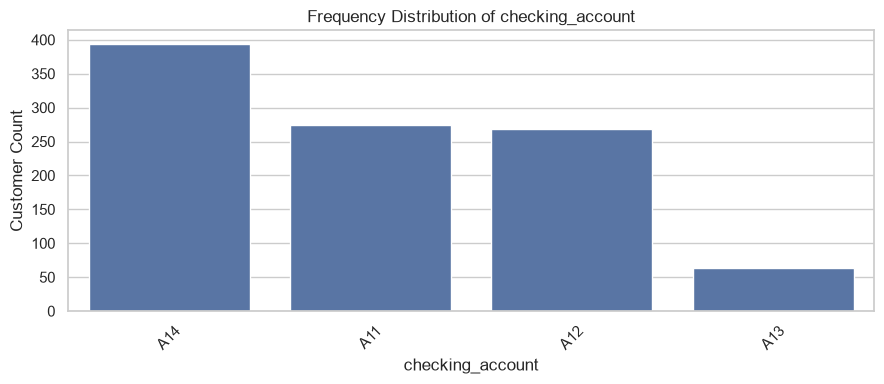

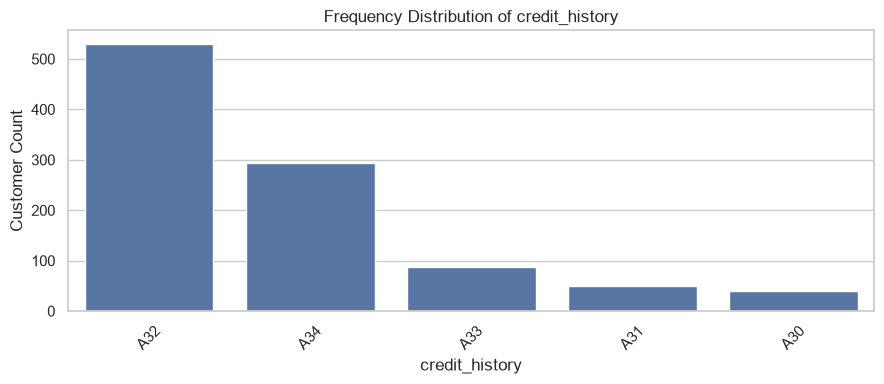

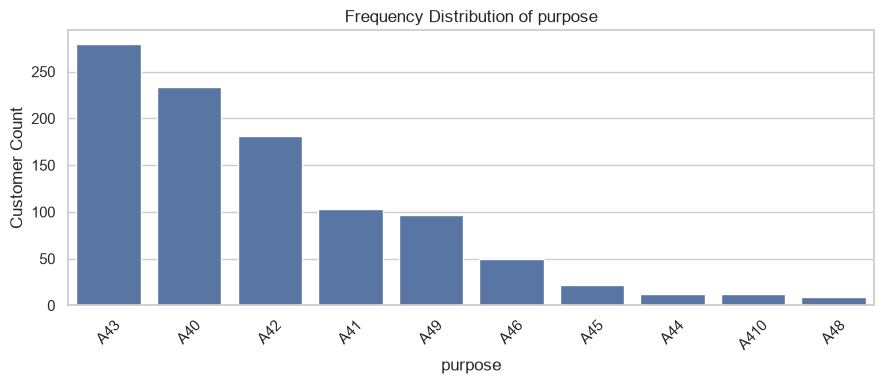

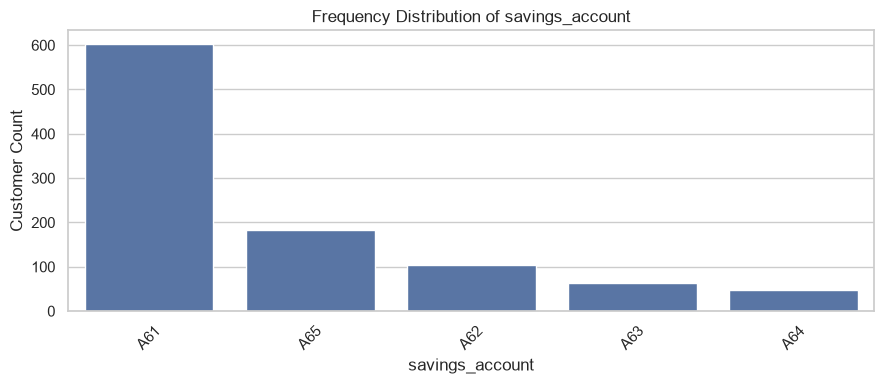

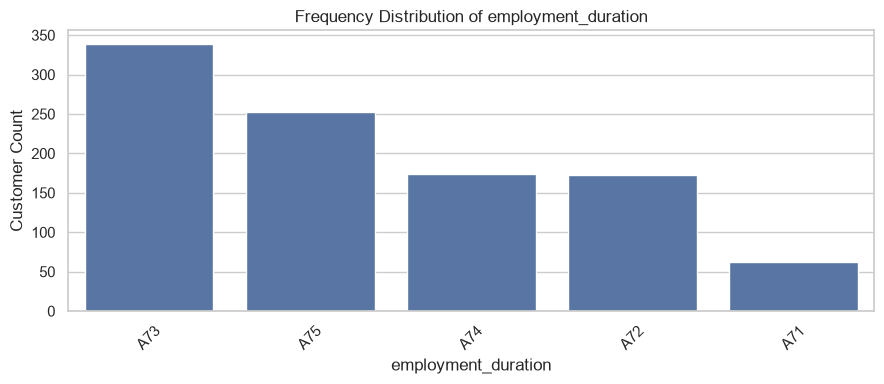

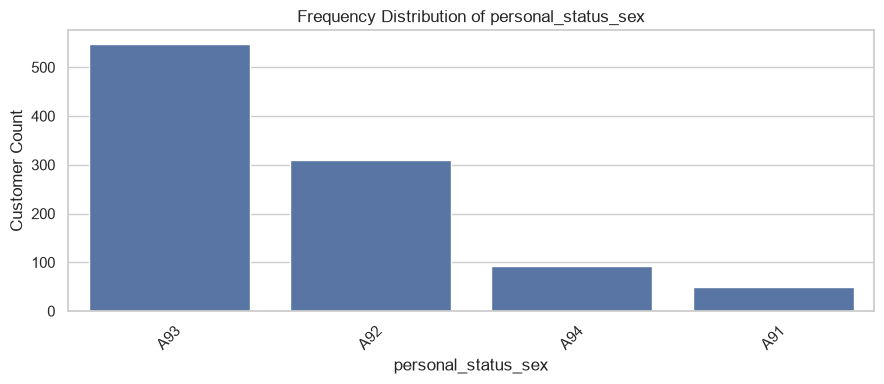

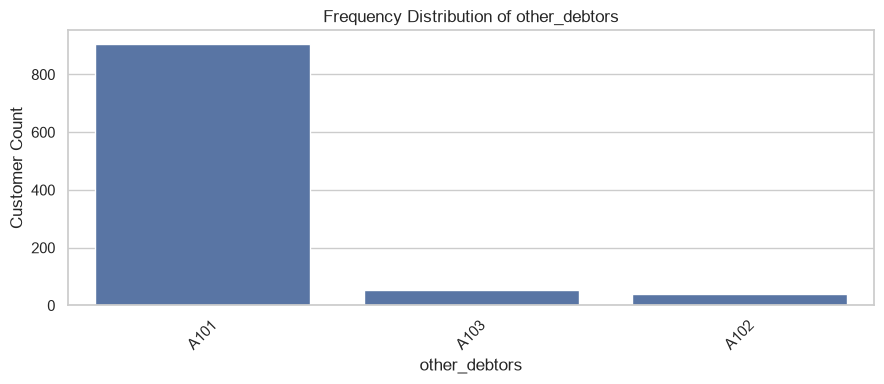

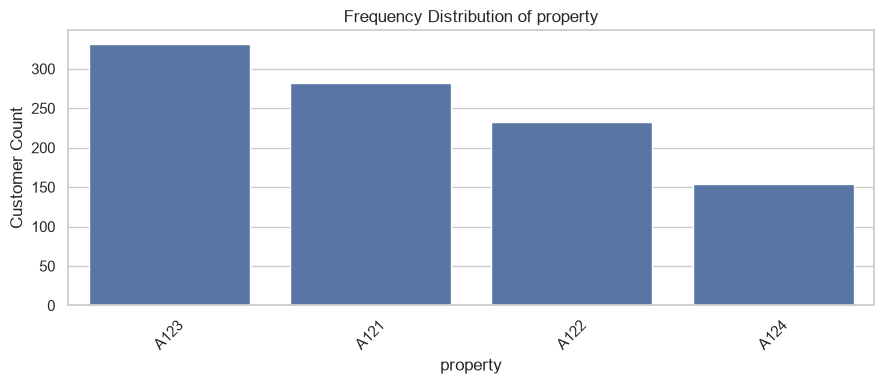

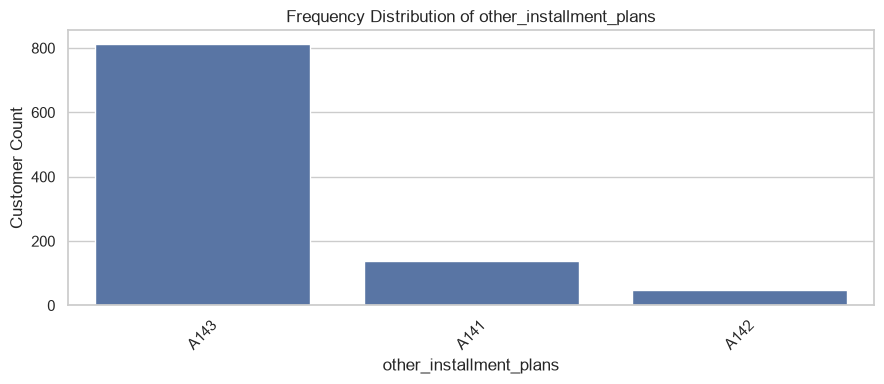

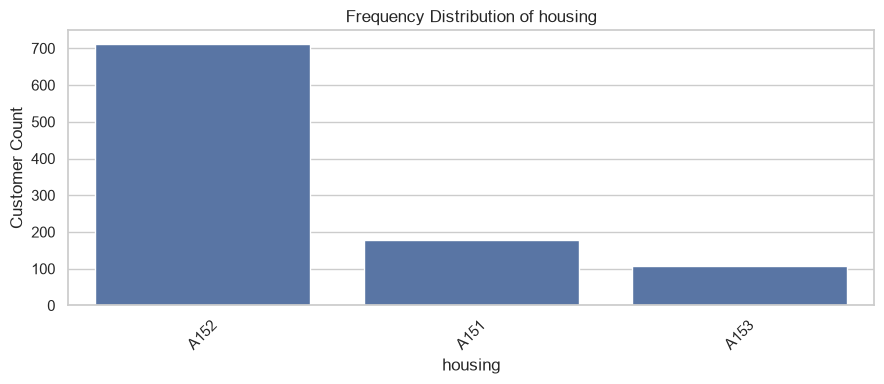

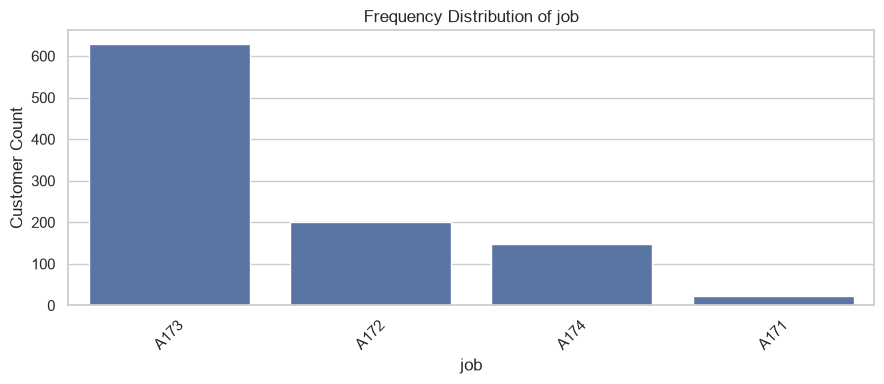

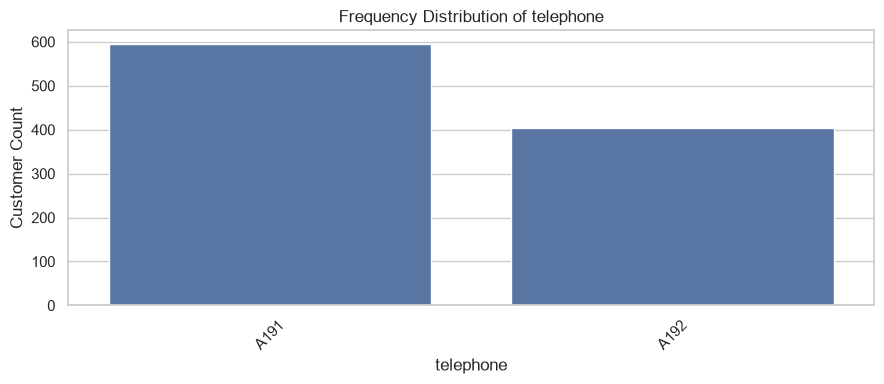

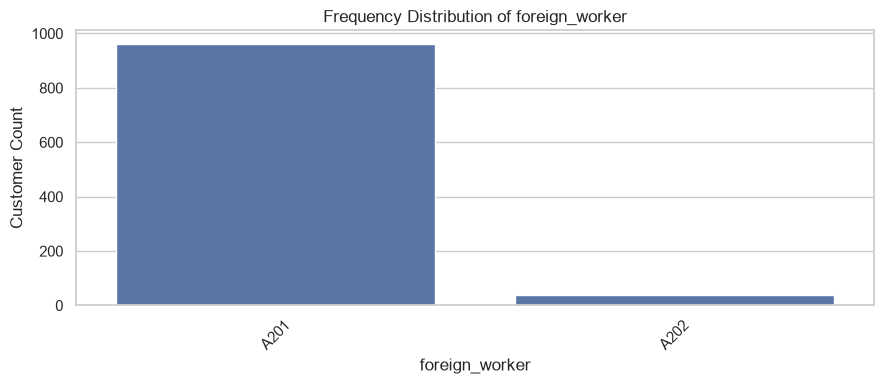

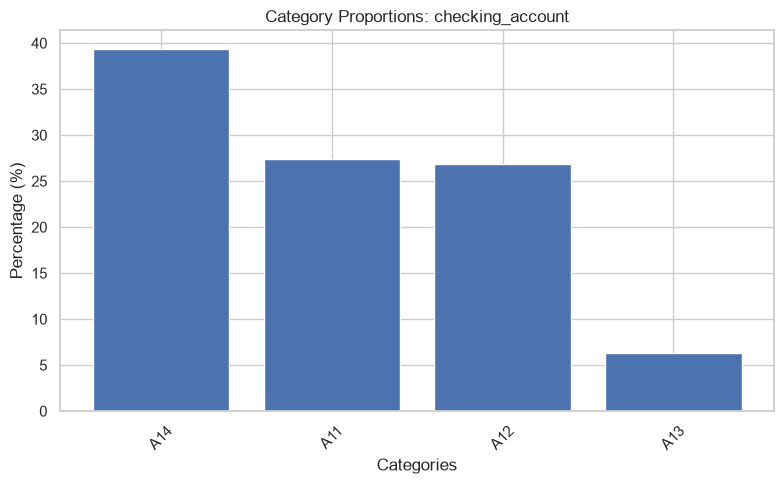

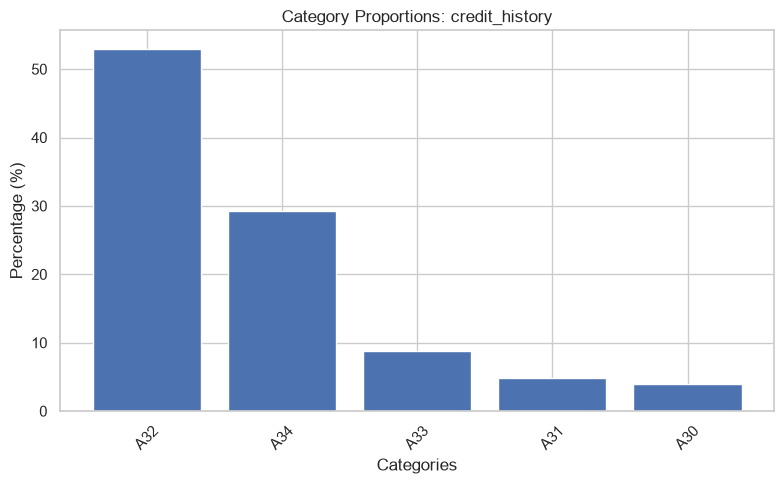

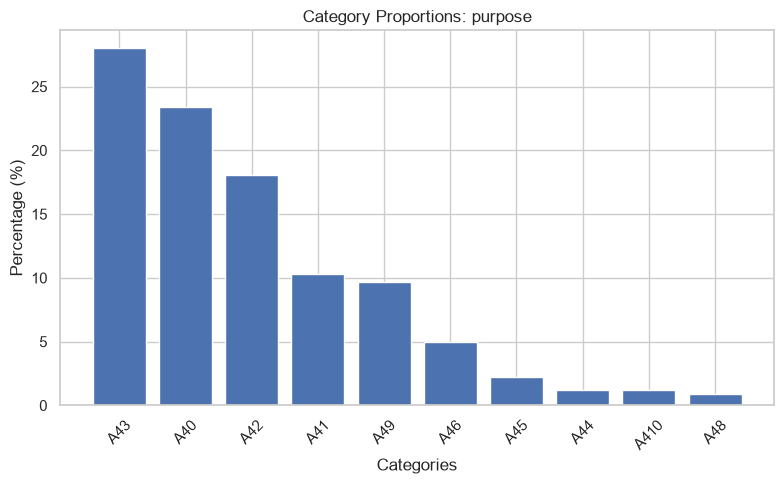

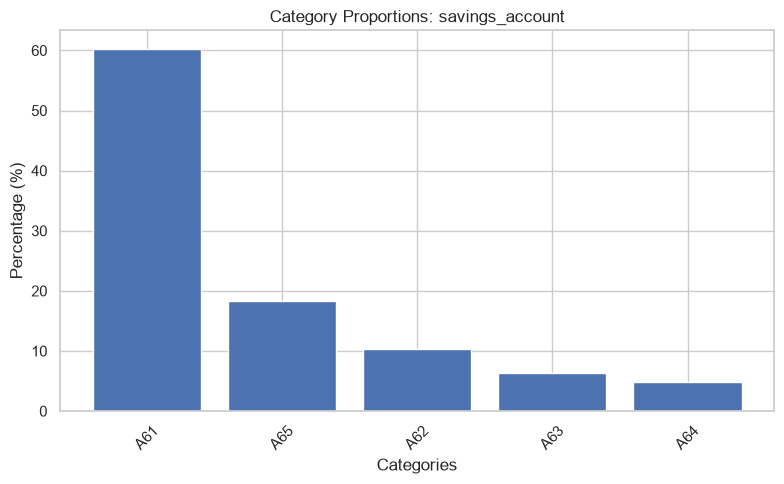

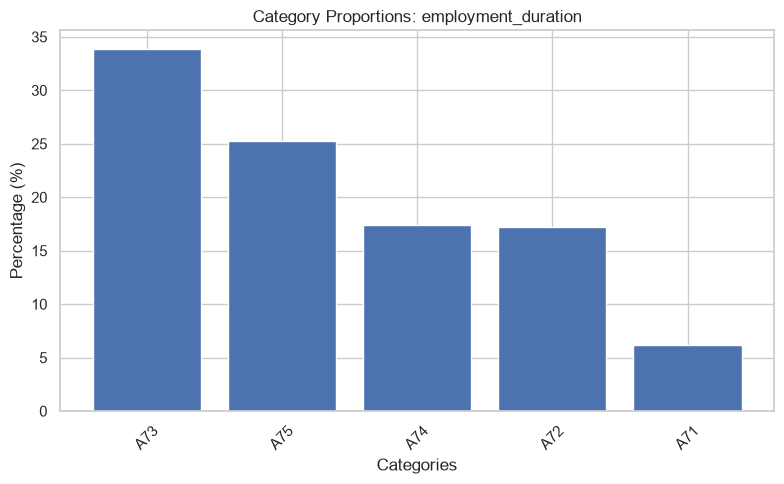

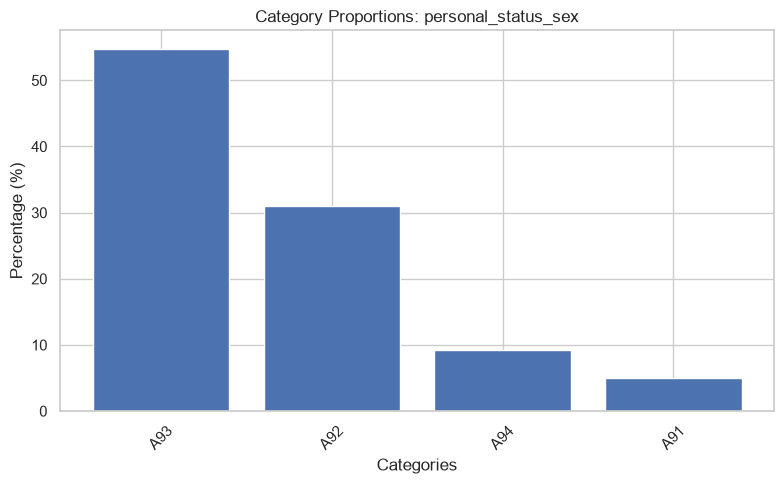

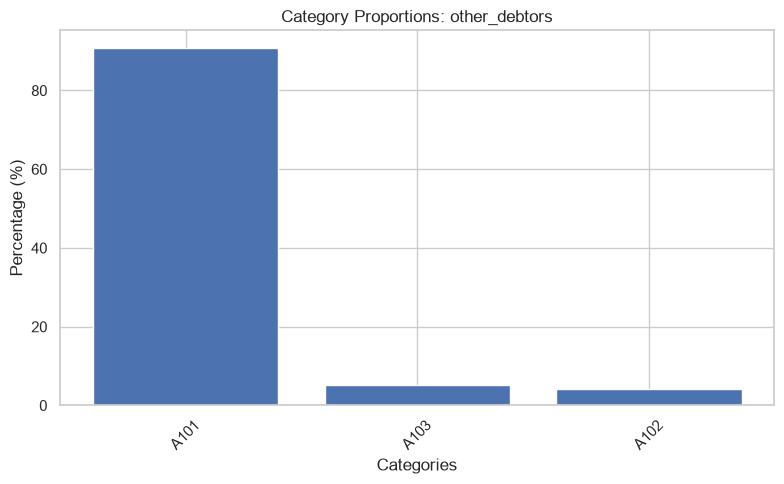

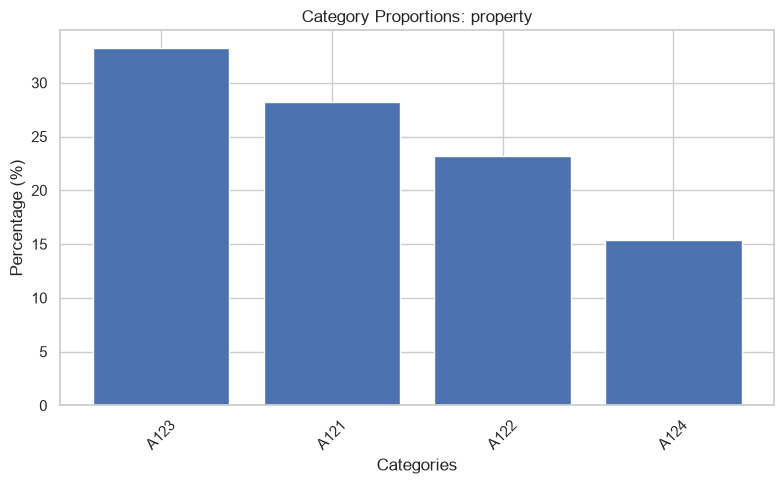

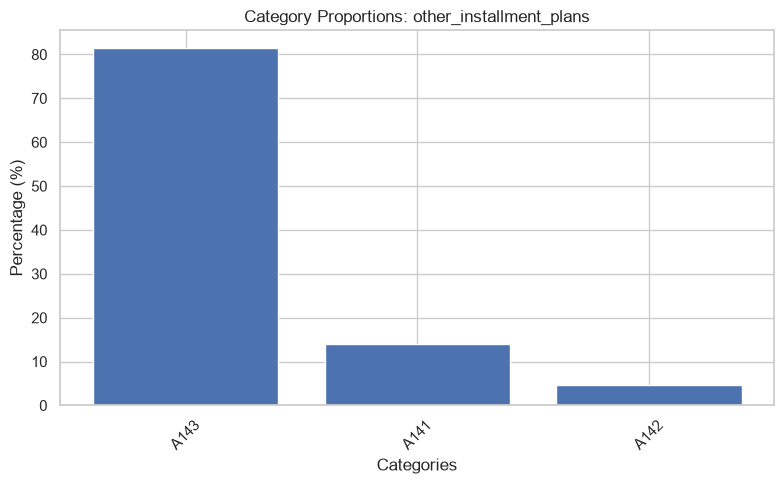

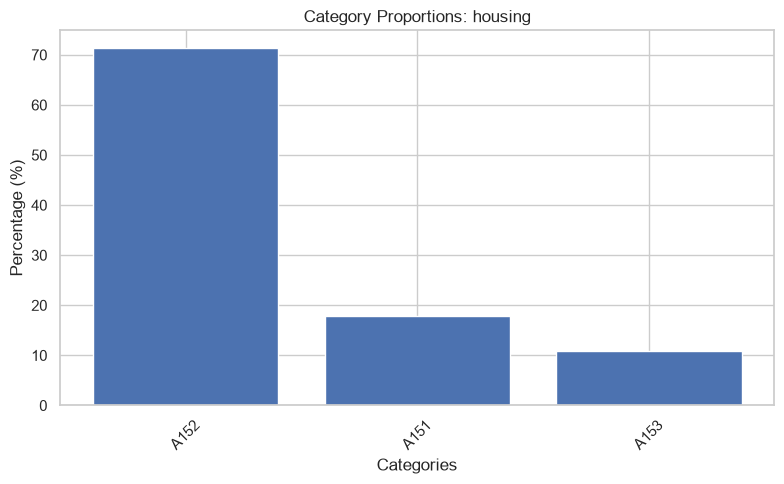

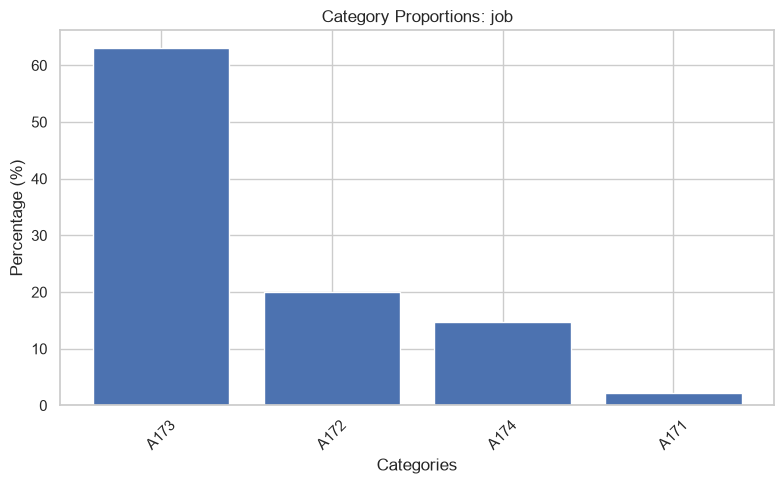

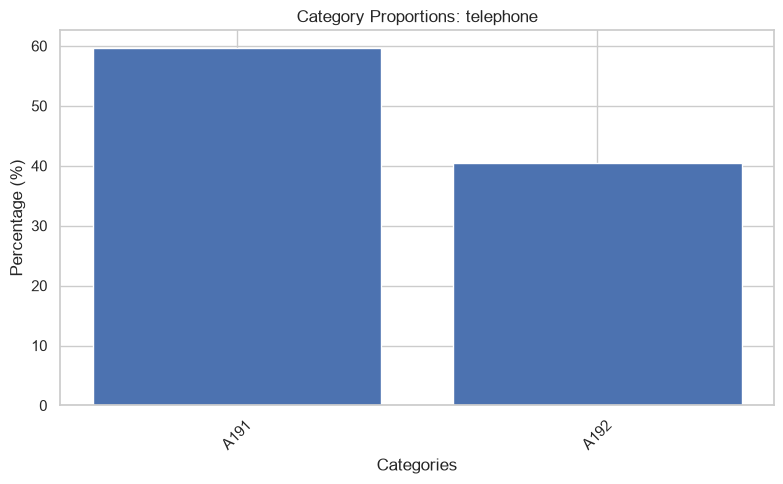

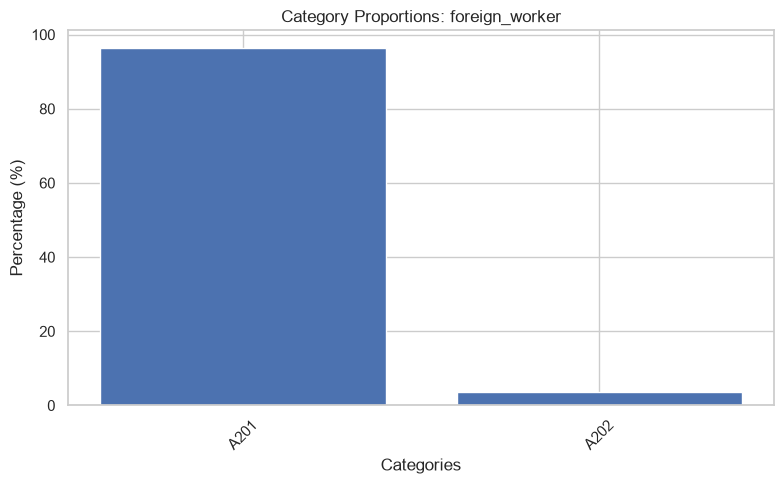


CATEGORICAL FEATURES VS CREDIT RISK

Credit Risk Analysis: checking_account


,Customer_Count,Bad_Credit_Rate
checking_account,,
A11,274,49.27
A12,269,39.03
A13,63,22.22
A14,394,11.68


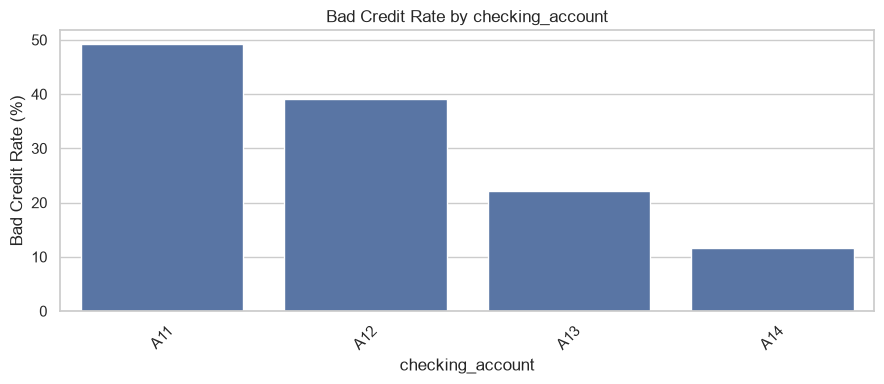


Credit Risk Analysis: credit_history


,Customer_Count,Bad_Credit_Rate
credit_history,,
A30,40,62.50
A31,49,57.14
A32,530,31.89
A33,88,31.82
A34,293,17.06


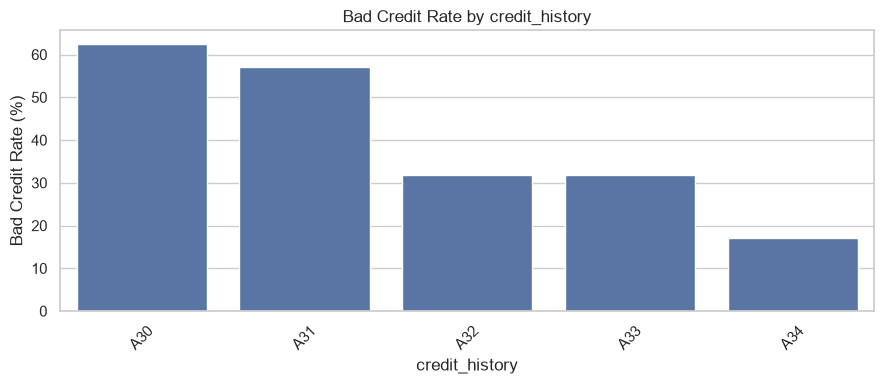


Credit Risk Analysis: purpose


,Customer_Count,Bad_Credit_Rate
purpose,,
A40,234,38.03
A41,103,16.50
A410,12,41.67
A42,181,32.04
A43,280,22.14
A44,12,33.33
A45,22,36.36
A46,50,44.00
A48,9,11.11


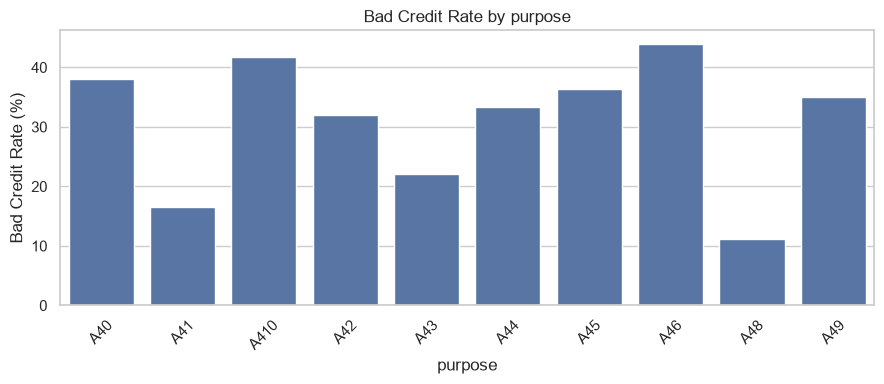


Credit Risk Analysis: savings_account


,Customer_Count,Bad_Credit_Rate
savings_account,,
A61,603,35.99
A62,103,33.01
A63,63,17.46
A64,48,12.50
A65,183,17.49


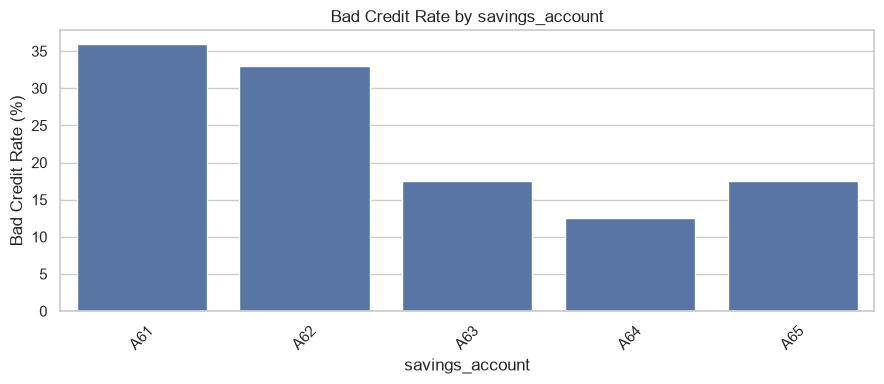


Credit Risk Analysis: employment_duration


,Customer_Count,Bad_Credit_Rate
employment_duration,,
A71,62,37.10
A72,172,40.70
A73,339,30.68
A74,174,22.41
A75,253,25.30


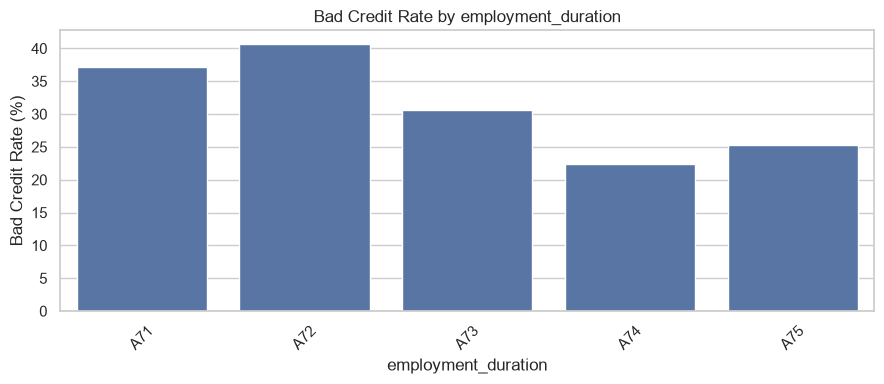


Credit Risk Analysis: personal_status_sex


,Customer_Count,Bad_Credit_Rate
personal_status_sex,,
A91,50,40.00
A92,310,35.16
A93,548,26.64
A94,92,27.17


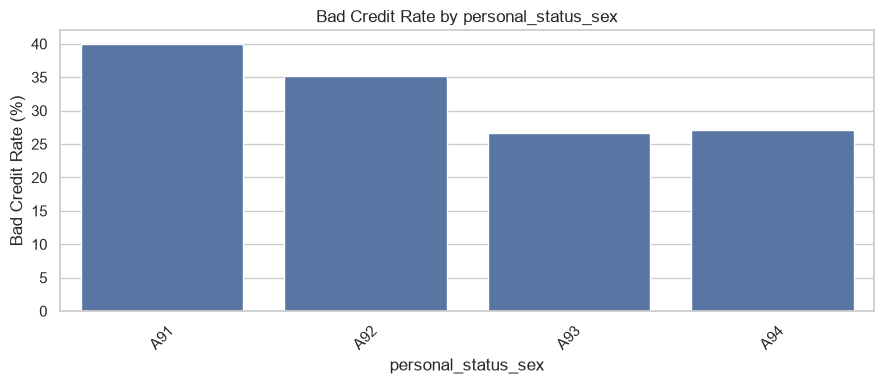


Credit Risk Analysis: other_debtors


,Customer_Count,Bad_Credit_Rate
other_debtors,,
A101,907,29.99
A102,41,43.90
A103,52,19.23


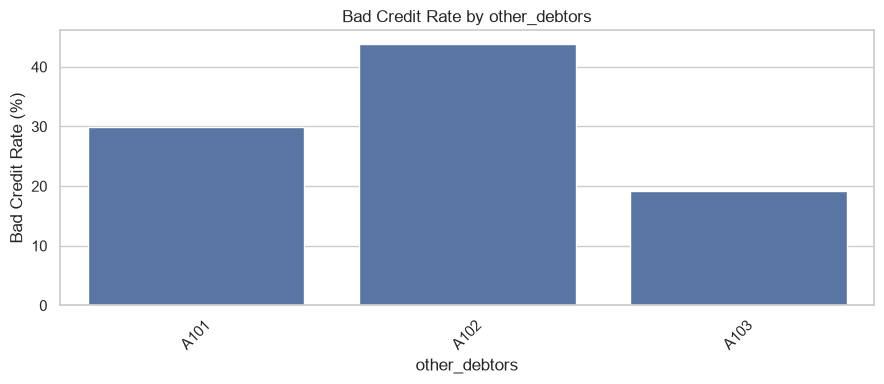


Credit Risk Analysis: property


,Customer_Count,Bad_Credit_Rate
property,,
A121,282,21.28
A122,232,30.60
A123,332,30.72
A124,154,43.51


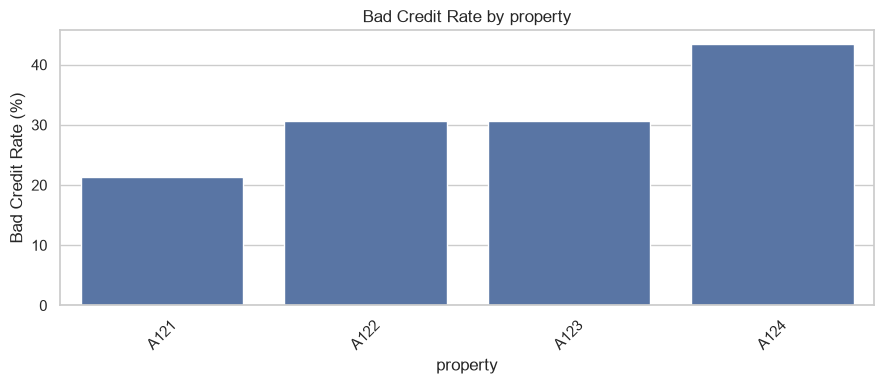


Credit Risk Analysis: other_installment_plans


,Customer_Count,Bad_Credit_Rate
other_installment_plans,,
A141,139,41.01
A142,47,40.43
A143,814,27.52


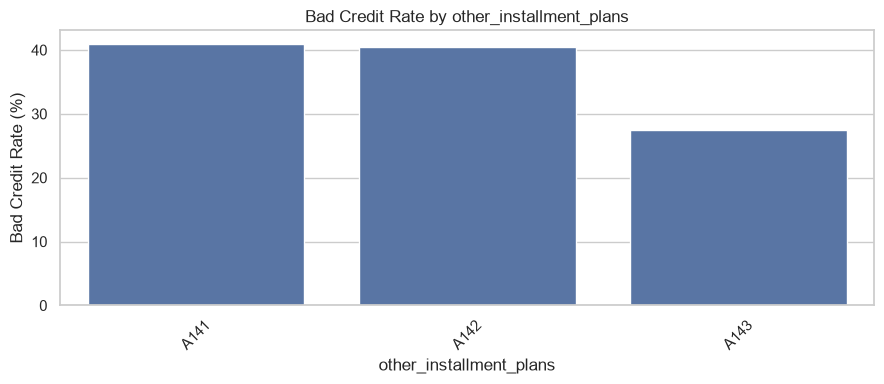


Credit Risk Analysis: housing


,Customer_Count,Bad_Credit_Rate
housing,,
A151,179,39.11
A152,713,26.09
A153,108,40.74


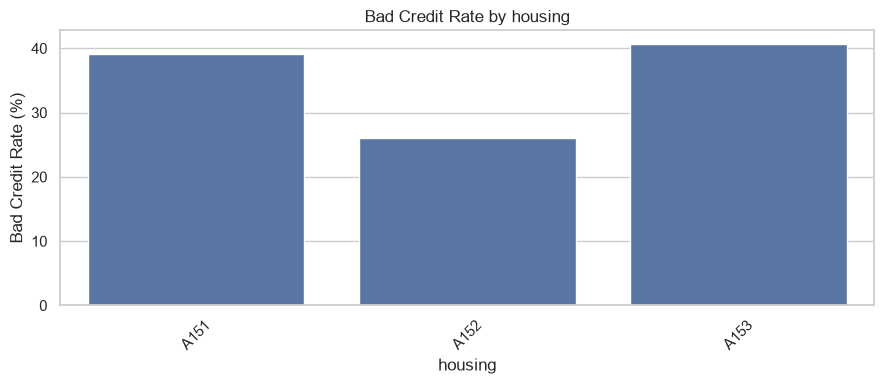


Credit Risk Analysis: job


,Customer_Count,Bad_Credit_Rate
job,,
A171,22,31.82
A172,200,28.00
A173,630,29.52
A174,148,34.46


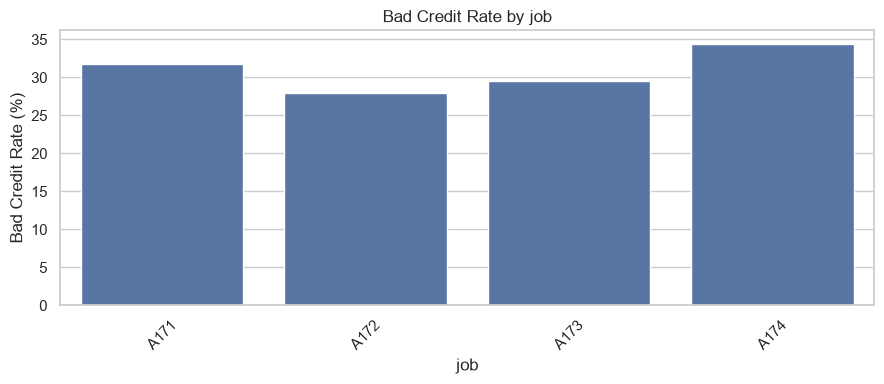


Credit Risk Analysis: telephone


,Customer_Count,Bad_Credit_Rate
telephone,,
A191,596,31.38
A192,404,27.97


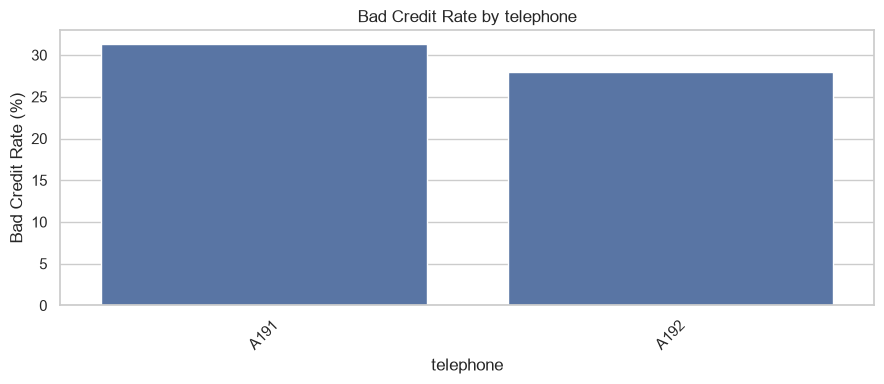


Credit Risk Analysis: foreign_worker


,Customer_Count,Bad_Credit_Rate
foreign_worker,,
A201,963,30.74
A202,37,10.81


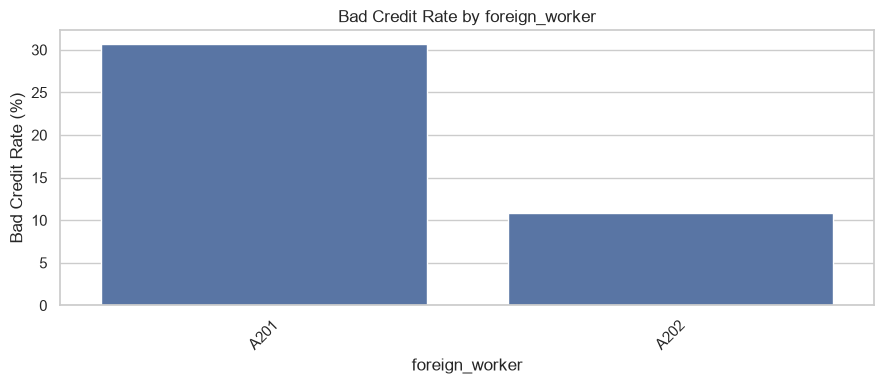


SPECIAL CATEGORY CREDIT RISK ANALYSIS

A65 Credit Risk Distribution:
risk_label
BAD      32
GOOD    151
dtype: int64

A124 Credit Risk Distribution:
risk_label
BAD     67
GOOD    87
dtype: int64

DOMAIN INTERPRETATION
1. Checking account categories describe customers' account status.
2. Credit history provides information about previous repayment behaviour.
3. Savings categories describe available savings information.
4. Employment duration indicates employment stability.
5. Property categories describe customer property information.
6. Housing categories describe accommodation status.
7. A65 represents unknown or no savings account.
8. A124 represents unknown or no property.
9. A65 and A124 are valid categorical values, not missing values.
10. Category-wise BAD credit rates help explore credit-risk patterns.

PREPROCESSING RECOMMENDATIONS
1. Preserve all original categorical codes.
2. Do not convert A65 or A124 into NaN.
3. Use One-Hot Encoding for nominal categorical features.
4. Co

In [7]:

# ============================================================
# SECTION 4: CATEGORICAL FEATURES - FREQUENCY AUDITING
# & SPECIAL ENCODINGS (A65, A124)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. IDENTIFY CATEGORICAL FEATURES

categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_duration",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

print("Total Categorical Features:", len(categorical_cols))
print("\nCategorical Features:")
print(categorical_cols)


# 2. UNIQUE CATEGORY AUDITING

print("\nUNIQUE CATEGORY AUDIT")
print("=" * 60)

for col in categorical_cols:
    print(f"\nFeature: {col}")
    print("Unique Categories:", df[col].nunique())
    print("Category Values:", sorted(df[col].unique()))


# 3. FREQUENCY AND PERCENTAGE ANALYSIS

print("\nFREQUENCY AND PERCENTAGE ANALYSIS")
print("=" * 60)

for col in categorical_cols:

    frequency = df[col].value_counts(dropna=False)
    percentage = df[col].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    frequency_table = pd.DataFrame({
        "Frequency": frequency,
        "Percentage": percentage
    })

    print(f"\nFeature: {col}")
    display(frequency_table.round(2))


# 4. MISSING VALUE AUDIT

print("\nMISSING VALUE AUDIT")

missing_summary = pd.DataFrame({
    "Missing_Count": df[categorical_cols].isnull().sum(),
    "Missing_Percentage": (
        df[categorical_cols].isnull().mean() * 100
    )
})

display(missing_summary.round(2))

print("Total Missing Categorical Values:",
      df[categorical_cols].isnull().sum().sum())


# 5. SPECIAL CATEGORY VERIFICATION: A65

print("\nA65 SPECIAL CATEGORY VERIFICATION")
print("=" * 60)

print("A65 Frequency:")
print((df["savings_account"] == "A65").sum())

print("\nSavings Account Distribution:")
print(df["savings_account"].value_counts())

assert "A65" in df["savings_account"].unique()
assert df.loc[
    df["savings_account"] == "A65",
    "savings_account"
].notna().all()

print("\nA65 VERIFIED: Retained as a valid category.")
print("Meaning: Unknown or no savings account.")


# 6. SPECIAL CATEGORY VERIFICATION: A124

print("\nA124 SPECIAL CATEGORY VERIFICATION")
print("=" * 60)

print("A124 Frequency:")
print((df["property"] == "A124").sum())

print("\nProperty Distribution:")
print(df["property"].value_counts())

assert "A124" in df["property"].unique()
assert df.loc[
    df["property"] == "A124",
    "property"
].notna().all()

print("\nA124 VERIFIED: Retained as a valid category.")
print("Meaning: Unknown or no property.")


# 7. VISUALIZE CATEGORICAL FREQUENCIES

for col in categorical_cols:

    plt.figure(figsize=(9, 4))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 8. CATEGORICAL PROPORTION ANALYSIS

for col in categorical_cols:

    proportions = (
        df[col].value_counts(normalize=True) * 100
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        proportions.index.astype(str),
        proportions.values
    )

    plt.title(f"Category Proportions: {col}")
    plt.xlabel("Categories")
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 9. CATEGORICAL FEATURES VS CREDIT RISK

print("\nCATEGORICAL FEATURES VS CREDIT RISK")
print("=" * 60)

for col in categorical_cols:

    risk_table = (
        df.groupby(col, observed=True)["credit_risk"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    risk_table["Bad_Credit_Rate"] *= 100

    print(f"\nCredit Risk Analysis: {col}")
    display(risk_table.round(2))

    #plotting block
    plot_data = risk_table.reset_index()

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=plot_data,
        x=col,
        y="Bad_Credit_Rate"
    )

    plt.title(f"Bad Credit Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Bad Credit Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 10. SPECIAL CATEGORY VS CREDIT RISK

print("\nSPECIAL CATEGORY CREDIT RISK ANALYSIS")

special_category_analysis = df[
    df["savings_account"] == "A65"
].groupby("risk_label").size()

print("\nA65 Credit Risk Distribution:")
print(special_category_analysis)

special_category_analysis_2 = df[
    df["property"] == "A124"
].groupby("risk_label").size()

print("\nA124 Credit Risk Distribution:")
print(special_category_analysis_2)


# 11. DOMAIN INTERPRETATION

print("\nDOMAIN INTERPRETATION")
print("=" * 60)

print("1. Checking account categories describe customers' account status.")
print("2. Credit history provides information about previous repayment behaviour.")
print("3. Savings categories describe available savings information.")
print("4. Employment duration indicates employment stability.")
print("5. Property categories describe customer property information.")
print("6. Housing categories describe accommodation status.")
print("7. A65 represents unknown or no savings account.")
print("8. A124 represents unknown or no property.")
print("9. A65 and A124 are valid categorical values, not missing values.")
print("10. Category-wise BAD credit rates help explore credit-risk patterns.")


# 12. PREPROCESSING RECOMMENDATIONS

print("\nPREPROCESSING RECOMMENDATIONS")
print("=" * 60)

print("1. Preserve all original categorical codes.")
print("2. Do not convert A65 or A124 into NaN.")
print("3. Use One-Hot Encoding for nominal categorical features.")
print("4. Consider Ordinal Encoding only where a meaningful order exists.")
print("5. Handle unknown categories consistently.")
print("6. Fit encoders using training data only.")
print("7. Check category frequencies before encoding.")


# 13. FINAL VALIDATION

assert len(categorical_cols) == 13
assert "A65" in df["savings_account"].values
assert "A124" in df["property"].values
assert df["savings_account"].isnull().sum() == 0
assert df["property"].isnull().sum() == 0

print("\n==============================================")
print("SECTION 4 COMPLETED SUCCESSFULLY")
print("==============================================")

print("Categorical Features Audited:", len(categorical_cols))
print("Frequency Analysis: Completed")
print("Percentage Analysis: Completed")
print("A65 Verification: PASSED")
print("A124 Verification: PASSED")
print("Missing Value Audit: Completed")
print("Credit Risk Analysis: Completed")
print("Domain Interpretation: Completed")


## Section 5: Bivariate Risk Analysis: Feature Relationships with Default Status


### Interpretation

*Write your interpretation here.*


## Section 6: Audit of Protected Attributes (Sex, Age, Foreign Worker)


### Interpretation

*Write your interpretation here.*


## Section 7: Summary of EDA Findings & Preprocessing Recommendations


### Interpretation

*Write your interpretation here.*
